# 00 · Radar from scratch

What a radar measures, built up one idea at a time, with a picture for each: waves, frequency and wavelength, phase,
complex numbers, decibels, speckle and coherence. Everything here is computed in the notebook; nothing is drawn by hand.

This is the foundation for the next notebooks, which use real Sentinel-1 and NISAR data over the Karakoram Highway:
01 finding and downloading data, 02 reading and cleaning backscatter, 03 interferometry and heights, 04 motion.

**How to use it.** Run the cells in order. Change the numbers (wavelength, distance, number of looks) and run again:
the point is to build intuition, not to read a result.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 3.2), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
rng = np.random.default_rng(42)          # a fixed seed: the same random numbers every run, so results are reproducible
c = 299_792_458.0                        # speed of light in vacuum, m/s

## 1 · A wave

A radar sends out an electromagnetic wave: an electric field that rises and falls as it travels. At one instant, along
the direction of travel, it looks like a sine curve. Two numbers describe it:

- **wavelength** $\lambda$: distance from one crest to the next (metres);
- **frequency** $f$: how many crests pass a fixed point per second (hertz).

They are tied by the speed of light: $c = f\,\lambda$, so $\lambda = c / f$.

In [2]:
bands = {"X (TerraSAR-X)": 9.65e9, "C (Sentinel-1)": 5.405e9, "S (NISAR S)": 3.2e9, "L (NISAR L)": 1.257e9, "P (Biomass)": 435e6}
for name, f in bands.items():
    print(f"{name:16s} f = {f/1e9:6.3f} GHz   wavelength = {100 * c / f:5.1f} cm")

X (TerraSAR-X)   f =  9.650 GHz   wavelength =   3.1 cm
C (Sentinel-1)   f =  5.405 GHz   wavelength =   5.5 cm
S (NISAR S)      f =  3.200 GHz   wavelength =   9.4 cm
L (NISAR L)      f =  1.257 GHz   wavelength =  23.8 cm
P (Biomass)      f =  0.435 GHz   wavelength =  68.9 cm


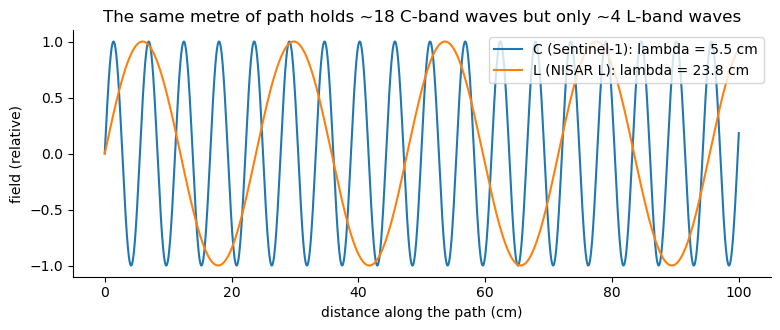

In [3]:
x = np.linspace(0, 1.0, 2000)            # one metre of path
fig, ax = plt.subplots()
for name in ("C (Sentinel-1)", "L (NISAR L)"):
    lam = c / bands[name]
    ax.plot(x * 100, np.sin(2 * np.pi * x / lam), label=f"{name}: lambda = {100 * lam:.1f} cm")
ax.set_xlabel("distance along the path (cm)"); ax.set_ylabel("field (relative)")
ax.set_title("The same metre of path holds ~18 C-band waves but only ~4 L-band waves"); ax.legend(loc="upper right")
plt.show()

**Why wavelength matters.** A wave interacts with things about its own size or bigger. C band (5.5 cm) is scattered by
leaves, twigs and gravel: it sees the top of a canopy. L band (24 cm) passes leaves and is scattered by trunks, branches
and the ground. For the Karakoram this decides whether two images taken 12 days apart still "agree" (section 7).

## 2 · Phase: where in its cycle the wave is

Phase is the position within one cycle, as an angle: 0 at a crest, $\pi$ at a trough, $2\pi$ back at a crest.
A wave that has travelled a distance $d$ has gone through $d/\lambda$ cycles, so its phase is

$$\varphi = 2\pi \frac{d}{\lambda} \pmod{2\pi}.$$

The "mod $2\pi$" is the key fact of interferometry: a receiver only sees the **fraction** of a cycle, never how many
whole cycles came before. 10.25 cycles and 3.25 cycles both look like a quarter cycle.

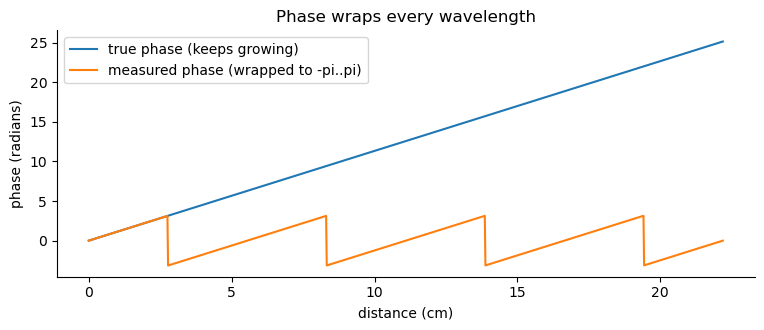

In [4]:
lam = c / bands["C (Sentinel-1)"]
d = np.linspace(0, 4 * lam, 1000)
phase_true = 2 * np.pi * d / lam
phase_seen = np.angle(np.exp(1j * phase_true))          # what an instrument can measure: wrapped to -pi..pi
fig, ax = plt.subplots()
ax.plot(d * 100, phase_true, label="true phase (keeps growing)")
ax.plot(d * 100, phase_seen, label="measured phase (wrapped to -pi..pi)")
ax.set_xlabel("distance (cm)"); ax.set_ylabel("phase (radians)"); ax.legend(); ax.set_title("Phase wraps every wavelength")
plt.show()

## 3 · Radar distance is a round trip

A radar measures the echo, so the wave goes out **and back**: the path is $2R$ for a target at range $R$. The phase of
the echo is therefore

$$\varphi = \frac{4\pi R}{\lambda} \pmod{2\pi}.$$

Move the target by half a wavelength (2.8 cm for Sentinel-1) and the round trip changes by a full wavelength: one full
phase cycle. That is why radar phase is sensitive to millimetres.

In [5]:
R0 = 850_000.0                          # about 850 km from satellite to ground
shifts_mm = np.array([0, 1, 5, 14, 27.7, 55.5])
phi = np.angle(np.exp(1j * 4 * np.pi * (R0 + shifts_mm / 1000) / lam))
phi0 = phi[0]
for s, p in zip(shifts_mm, phi):
    print(f"target moved {s:5.1f} mm  ->  phase change {np.angle(np.exp(1j * (p - phi0))):+.3f} rad")

target moved   0.0 mm  ->  phase change +0.000 rad
target moved   1.0 mm  ->  phase change +0.227 rad
target moved   5.0 mm  ->  phase change +1.133 rad
target moved  14.0 mm  ->  phase change -3.111 rad
target moved  27.7 mm  ->  phase change -0.007 rad
target moved  55.5 mm  ->  phase change +0.008 rad


## 4 · Complex numbers: amplitude and phase in one value

Each pixel of a single-look complex (SLC) image is a complex number $s = A e^{i\varphi} = A\cos\varphi + iA\sin\varphi$.

- $|s| = A$ is the **amplitude**: how strong the echo is. $|s|^2$ is the **power** (intensity).
- $\arg s = \varphi$ is the **phase**.

Picture it as an arrow on a plane: length = amplitude, angle = phase. Adding echoes means adding arrows.

complex value: (0.4+0.693j)
amplitude |s| = 0.8   power |s|^2 = 0.64   phase = 60.0 degrees


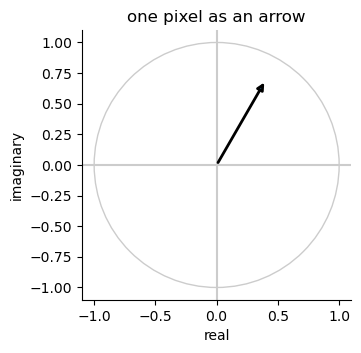

In [6]:
s = 0.8 * np.exp(1j * np.radians(60))
print("complex value:", np.round(s, 3))
print("amplitude |s| =", round(abs(s), 3), "  power |s|^2 =", round(abs(s) ** 2, 3), "  phase =", round(np.degrees(np.angle(s)), 1), "degrees")
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.8"))
ax.annotate("", xy=(s.real, s.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2))
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal"); ax.axhline(0, color="0.8"); ax.axvline(0, color="0.8")
ax.set_xlabel("real"); ax.set_ylabel("imaginary"); ax.set_title("one pixel as an arrow")
plt.show()

## 5 · Speckle: why one radar image looks grainy

A 10 m pixel contains many scatterers (stones, leaves, edges), each returning a small arrow with its own phase. The pixel
value is the **sum** of those arrows. Because their phases are effectively random, the sum is a random walk: sometimes
they line up (bright), sometimes they cancel (dark). That is **speckle**: not noise from the instrument, but real
interference. Its key property, for a uniform surface, is that the intensity follows an exponential distribution:
standard deviation equal to the mean. One look is very uncertain.

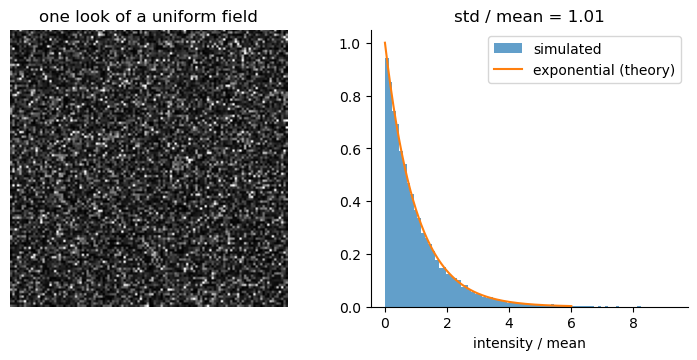

In [7]:
def pixel(n_scatterers=50):
    arrows = rng.rayleigh(1.0, n_scatterers) * np.exp(1j * rng.uniform(-np.pi, np.pi, n_scatterers))
    return arrows.sum()

field = np.array([[pixel() for _ in range(120)] for _ in range(120)])     # a perfectly uniform field
I = np.abs(field) ** 2
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
axs[0].imshow(I, cmap="gray", vmax=np.percentile(I, 99)); axs[0].set_title("one look of a uniform field"); axs[0].axis("off")
axs[1].hist(I.ravel() / I.mean(), bins=80, density=True, alpha=0.7, label="simulated")
xx = np.linspace(0, 6, 200); axs[1].plot(xx, np.exp(-xx), label="exponential (theory)")
axs[1].set_xlabel("intensity / mean"); axs[1].legend(); axs[1].set_title(f"std / mean = {I.std() / I.mean():.2f}")
plt.show()

## 6 · Multilooking and despeckling: averaging, in the right units

Averaging $L$ independent looks cuts the relative spread by $\sqrt{L}$. Two rules that are easy to get wrong:

1. **Average power (linear), never decibels.** The log of an average is not the average of logs; averaging dB biases
   dark.
2. Averaging trades resolution for certainty. A 5 x 5 window gives 25 looks and 5 x coarser pixels. Smarter filters
   (Lee, refined Lee, Gamma-MAP) average more on flat areas and less across edges.

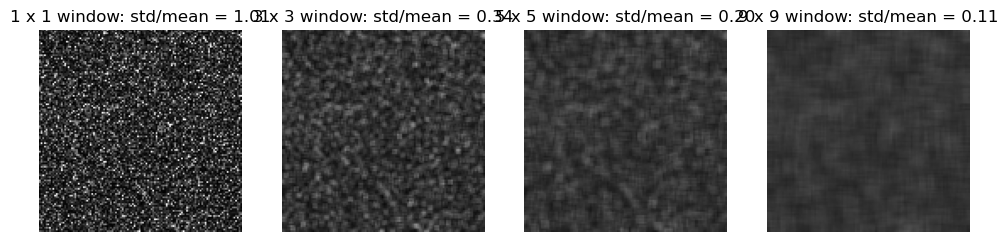

average in linear, then dB: 19.95 dB;   average of dB values: 17.43 dB  (biased low by 2.52 dB)


In [8]:
from scipy.ndimage import uniform_filter
fig, axs = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, L in zip(axs, (1, 3, 5, 9)):
    m = uniform_filter(I, L) if L > 1 else I
    ax.imshow(m, cmap="gray", vmin=0, vmax=np.percentile(I, 99)); ax.axis("off")
    ax.set_title(f"{L} x {L} window: std/mean = {m.std() / m.mean():.2f}")
plt.show()
L = 5
lin_then_db = 10 * np.log10(uniform_filter(I, L).mean())
db_then_avg = uniform_filter(10 * np.log10(I), L).mean()
print(f"average in linear, then dB: {lin_then_db:.2f} dB;   average of dB values: {db_then_avg:.2f} dB  (biased low by {lin_then_db - db_then_avg:.2f} dB)")

## 7 · Decibels: a log scale for a huge range

Backscatter $\sigma^0$ ranges from about 0.001 (calm water) to over 10 (a corner reflector). On a linear scale the bright
few hide everything else. The decibel is $10\log_{10}$ of a power ratio:

$$\sigma^0_{dB} = 10\log_{10}\sigma^0, \qquad \sigma^0 = 10^{\sigma^0_{dB}/10}.$$

Rules of thumb: +3 dB is double the power, +10 dB ten times, -10 dB a tenth. Because $\sigma^0$ is a power, the factor
is 10, not 20 (20 is for amplitudes).

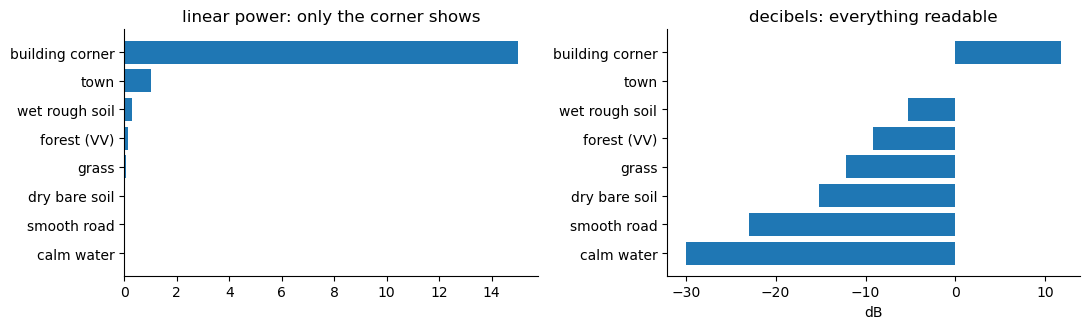

In [9]:
targets = {"calm water": 0.001, "smooth road": 0.005, "dry bare soil": 0.03, "grass": 0.06, "forest (VV)": 0.12,
           "wet rough soil": 0.3, "town": 1.0, "building corner": 15}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
names = list(targets); v = np.array(list(targets.values()))
axs[0].barh(names, v); axs[0].set_title("linear power: only the corner shows")
axs[1].barh(names, 10 * np.log10(v)); axs[1].set_title("decibels: everything readable"); axs[1].set_xlabel("dB")
plt.tight_layout(); plt.show()

## 8 · Interferometry: two images, one phase difference

Two passes see the same pixel. Each pixel's phase is (speckle phase) + $4\pi R/\lambda$. Speckle is random, so one
image's phase is useless; but if nothing on the ground changed, the speckle phase is **the same** in both. Multiply
image 1 by the complex conjugate of image 2:

$$s_1 s_2^* = A_1A_2\,e^{i(\varphi_1-\varphi_2)}, \qquad \varphi_1-\varphi_2 = \frac{4\pi}{\lambda}(R_1-R_2).$$

The random part cancels and the difference in distance remains. The same cancellation fails if the scatterers moved or
changed between passes: that is **decorrelation**.

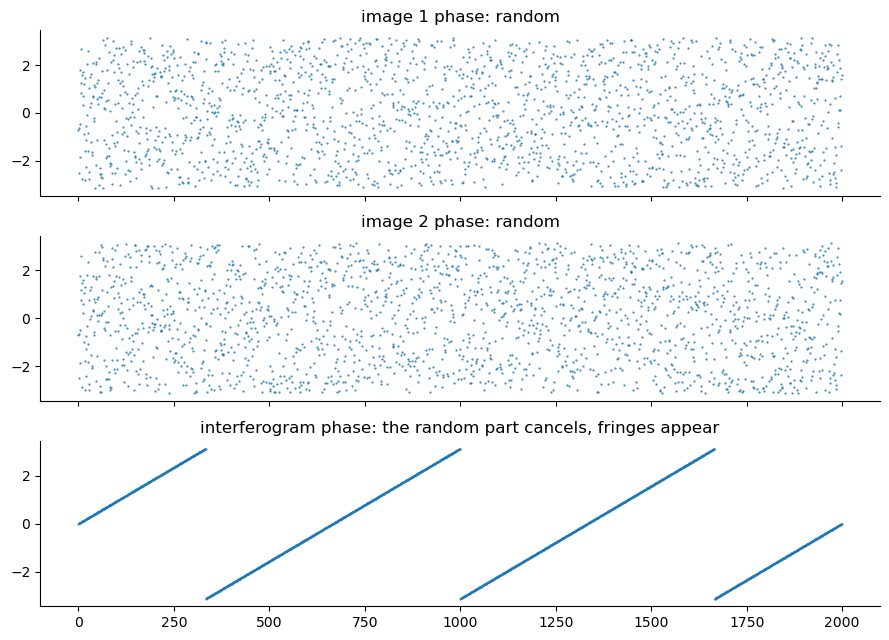

In [10]:
n = 2000
speckle = rng.uniform(-np.pi, np.pi, n)
signal = np.linspace(0, 6 * np.pi, n)                          # a smooth difference in range, e.g. a slope
s1 = np.exp(1j * speckle)
s2 = np.exp(1j * (speckle - signal))
fig, axs = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
axs[0].plot(np.angle(s1), ".", ms=1); axs[0].set_title("image 1 phase: random")
axs[1].plot(np.angle(s2), ".", ms=1); axs[1].set_title("image 2 phase: random")
axs[2].plot(np.angle(s1 * np.conj(s2)), ".", ms=1); axs[2].set_title("interferogram phase: the random part cancels, fringes appear")
plt.tight_layout(); plt.show()

## 9 · Coherence: how much the two images still agree

Coherence $\gamma$ (0 to 1) is estimated in a small window:

$$\hat\gamma = \frac{\left|\sum s_1 s_2^*\right|}{\sqrt{\sum|s_1|^2\sum|s_2|^2}}.$$

If every pixel in the window has the same phase difference, the arrows of $s_1s_2^*$ line up and $\gamma \to 1$. If
the scatterers changed (leaves moved, snow fell, a slope slid), the differences are random, the arrows cancel and
$\gamma \to 0$. Low coherence means the phase there carries no information. Note a trap: steep terrain makes the phase
change *inside* the window, which also lowers $\hat\gamma$ unless the local fringe slope is removed first.

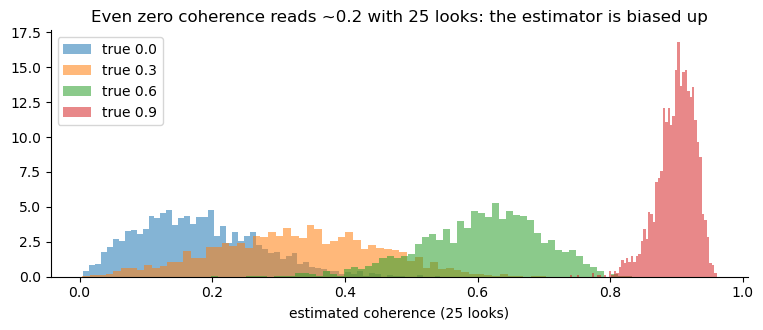

In [11]:
def coherence(true_gamma, n=25, trials=2000):
    out = []
    for _ in range(trials):
        common = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
        own1 = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
        own2 = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
        a = np.sqrt(true_gamma) * common + np.sqrt(1 - true_gamma) * own1
        b = np.sqrt(true_gamma) * common + np.sqrt(1 - true_gamma) * own2
        out.append(np.abs((a * np.conj(b)).sum()) / np.sqrt((np.abs(a) ** 2).sum() * (np.abs(b) ** 2).sum()))
    return np.array(out)

fig, ax = plt.subplots()
for g in (0.0, 0.3, 0.6, 0.9):
    ax.hist(coherence(g), bins=60, alpha=0.55, density=True, label=f"true {g}")
ax.set_xlabel("estimated coherence (25 looks)"); ax.legend(); ax.set_title("Even zero coherence reads ~0.2 with 25 looks: the estimator is biased up")
plt.show()

## 10 · Summary: the words, in one place

| term | meaning | unit |
|---|---|---|
| wavelength $\lambda$ | crest-to-crest distance; C 5.5 cm, L 24 cm | m |
| frequency $f$ | cycles per second, $f = c/\lambda$ | Hz |
| phase $\varphi$ | position in the cycle, known only mod $2\pi$ | rad |
| amplitude, power | arrow length, its square | -, linear |
| $\sigma^0$, $\gamma^0$ | calibrated backscatter per ground area / per area facing the radar | linear or dB |
| decibel | $10\log_{10}$ of a power ratio | dB |
| speckle | interference of many scatterers in a pixel; std = mean for one look | - |
| looks | independent samples averaged | count |
| interferogram | $s_1 s_2^*$: phase difference of two passes | rad |
| coherence $\gamma$ | agreement of two images in a window | 0-1 |
| baseline $B_\perp$ | separation of the two orbits, across the look direction | m |
| height of ambiguity $h_a$ | height change for one fringe: $\lambda R\sin\theta/(2B_\perp)$ | m |

Next: **01 · Finding and downloading radar data**: querying the Alaska Satellite Facility catalogue by point, polygon,
date, track and product; reading baselines; downloading safely.